# This notebook represent multimodel training 

In [22]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

### 1. Load data set

In [8]:
# Load scaled features and target
X_train_scaled = np.load("../data/processed/X_train_scaled.npy")
X_test_scaled  = np.load("../data/processed/X_test_scaled.npy")
y_train_scaled = np.load("../data/processed/y_train_scaled.npy")
y_test_scaled  = np.load("../data/processed/y_test_scaled.npy")

# Load original target for evaluation
y_train = np.load("../data/processed/y_train.npy")
y_test  = np.load("../data/processed/y_test.npy")

# Load scalers
scaler_X = joblib.load("../artifacts/scalers/scaler_X.pkl")
scaler_y = joblib.load("../artifacts/scalers/scaler_y.pkl")

# Load selected feature names
selected_features = joblib.load("../artifacts/scalers/selected_features.pkl")

print("Data loaded successfully!")
print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape :", X_test_scaled.shape)
print("y_train shape       :", y_train.shape)
print("y_test shape        :", y_test.shape)
print("Number of features  :", len(selected_features))

Data loaded successfully!
X_train_scaled shape: (15759, 24)
X_test_scaled shape : (3940, 24)
y_train shape       : (15759,)
y_test shape        : (3940,)
Number of features  : 24


### 2. Define multi model

In [10]:
models = {
            "Linear Regression": LinearRegression(),
            "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
            "XGBoost": XGBRegressor(n_estimators=100, random_state=42)
            }

### 3. Train models

In [12]:
trained_models = {}

print("Starting Model Training...\n")

for model_name, model in models.items():
    print(f"Training {model_name}...")
    model.fit(X_train_scaled, y_train)
    trained_models[model_name] = model
    print(f"{model_name} trained successfully!\n")

print("All models trained successfully!")

Starting Model Training...

Training Linear Regression...
Linear Regression trained successfully!

Training Random Forest...
Random Forest trained successfully!

Training XGBoost...
XGBoost trained successfully!

All models trained successfully!


### 4. Evaluation models

In [14]:
def evaluate_model(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    
    print(f"{model_name} Results:")
    print(f"  MAE  : {mae:.4f}")
    print(f"  RMSE : {rmse:.4f}")
    print(f"  R²   : {r2:.4f}\n")
    
    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

In [15]:
results = []

print("Starting Model Evaluation...\n")

for model_name, model in trained_models.items():
    y_pred = model.predict(X_test_scaled)
    result = evaluate_model(y_test, y_pred, model_name)
    results.append(result)

Starting Model Evaluation...

Linear Regression Results:
  MAE  : 26.4381
  RMSE : 59.7238
  R²   : 0.5644

Random Forest Results:
  MAE  : 53.3231
  RMSE : 87.3507
  R²   : 0.0681

XGBoost Results:
  MAE  : 113.3462
  RMSE : 155.0843
  R²   : -1.9375



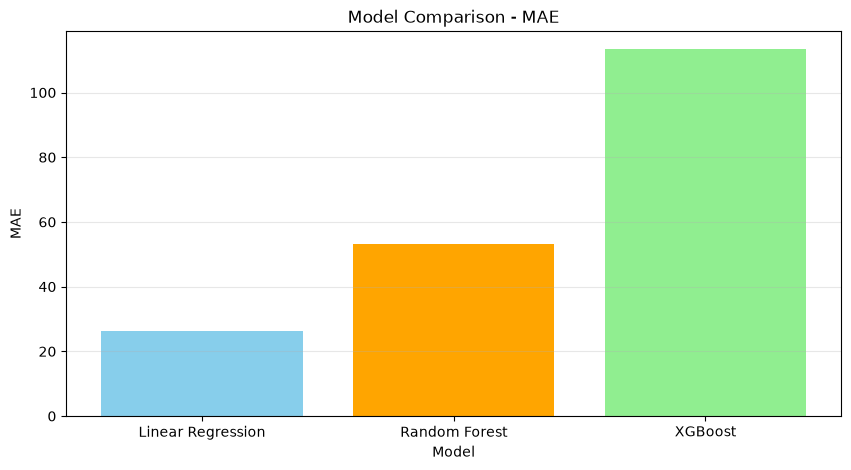

In [20]:
plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["MAE"], color=["skyblue", "orange", "lightgreen"])
plt.title("Model Comparison - MAE")
plt.ylabel("MAE")
plt.xlabel("Model")
plt.grid(axis='y', alpha=0.3)
plt.show()

### 5. Save best model

In [17]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="MAE").reset_index(drop=True)

print("Baseline Models Performance Comparison:")
display(results_df)

Baseline Models Performance Comparison:


,Model,MAE,RMSE,R2
0,Linear Regression,26.438120,59.723763,0.564356
1,Random Forest,53.323096,87.350708,0.068099
2,XGBoost,113.346222,155.084270,-1.937464


In [18]:
os.makedirs("../artifacts/models", exist_ok=True)

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

save_path = f"../artifacts/models/{best_model_name.replace(' ', '_').lower()}_model.pkl"
joblib.dump(best_model, save_path)

print(f"Best model '{best_model_name}' saved at: {save_path}")

Best model 'Linear Regression' saved at: ../artifacts/models/linear_regression_model.pkl


### 6. Hyper parameter tuning

### 6.1 Define parameter grid

In [24]:
# Parameter grid for Random Forest
rf_param_grid = {
    "n_estimators": [50, 100, 150, 200],
    "max_depth": [6, 8, 10, 12, 15],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

# Parameter grid for XGBoost
xgb_param_grid = {
    "n_estimators": [50, 100, 150, 200],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

### 6.2 Time Series Cross Validation

In [26]:
# Use TimeSeriesSplit instead of normal KFold
tscv = TimeSeriesSplit(n_splits=3)

### 6.3 Tune Random Forest

In [28]:
print("Tuning Random Forest...")

rf = RandomForestRegressor(random_state=42, n_jobs=-1)

rf_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=rf_param_grid,
    n_iter=15,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

rf_search.fit(X_train_scaled, y_train)

print("Best Random Forest Parameters:")
print(rf_search.best_params_)
print(f"Best CV MAE: {-rf_search.best_score_:.4f}")

best_rf = rf_search.best_estimator_

Tuning Random Forest...
Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best Random Forest Parameters:
{'n_estimators': 150, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': 10}
Best CV MAE: 34.3133


### 6.4 Tune XGBoost

In [30]:
print("\nTuning XGBoost...")

xgb = XGBRegressor(random_state=42, n_jobs=-1)

xgb_search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=xgb_param_grid,
    n_iter=15,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

xgb_search.fit(X_train_scaled, y_train)

print("Best XGBoost Parameters:")
print(xgb_search.best_params_)
print(f"Best CV MAE: {-xgb_search.best_score_:.4f}")

best_xgb = xgb_search.best_estimator_


Tuning XGBoost...
Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best XGBoost Parameters:
{'subsample': 0.8, 'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
Best CV MAE: 30.8110


### 6.5 Evaluate Tuned Models on Test Set

In [32]:
def evaluate_model(y_true, y_pred, model_name):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    
    print(f"\n{model_name} Results:")
    print(f"  MAE  : {mae:.4f}")
    print(f"  RMSE : {rmse:.4f}")
    print(f"  R²   : {r2:.4f}")
    
    return {"Model": model_name, "MAE": mae, "RMSE": rmse, "R2": r2}


tuned_results = []

# Evaluate Tuned Random Forest
y_pred_rf = best_rf.predict(X_test_scaled)
tuned_results.append(evaluate_model(y_test, y_pred_rf, "Tuned Random Forest"))

# Evaluate Tuned XGBoost
y_pred_xgb = best_xgb.predict(X_test_scaled)
tuned_results.append(evaluate_model(y_test, y_pred_xgb, "Tuned XGBoost"))


Tuned Random Forest Results:
  MAE  : 33.3757
  RMSE : 62.6491
  R²   : 0.5206

Tuned XGBoost Results:
  MAE  : 28.0657
  RMSE : 58.6780
  R²   : 0.5795


### 6.6 Compare Before vs After Tuning

In [34]:
tuned_results_df = pd.DataFrame(tuned_results)
print("\nTuned Models Performance:")
display(tuned_results_df)


Tuned Models Performance:


,Model,MAE,RMSE,R2
0,Tuned Random Forest,33.375656,62.649100,0.520635
1,Tuned XGBoost,28.065720,58.678004,0.579479


C:\Users\naduk\AppData\Local\Temp\ipykernel_25396\3068073907.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tuned_results_df, x="Model", y="MAE", palette="viridis")


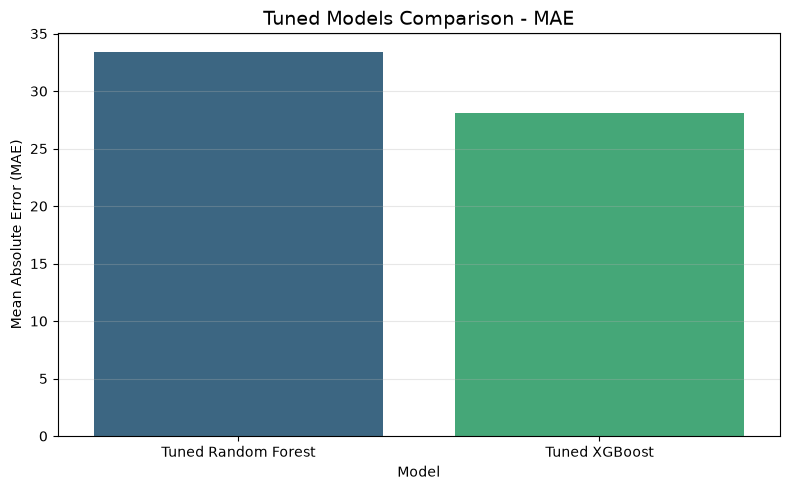

In [36]:
plt.figure(figsize=(8, 5))
sns.barplot(data=tuned_results_df, x="Model", y="MAE", palette="viridis")

plt.title("Tuned Models Comparison - MAE", fontsize=14)
plt.ylabel("Mean Absolute Error (MAE)")
plt.xlabel("Model")
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 6.7 Save tuned models

In [38]:
# Select best tuned model
best_tuned_name = tuned_results_df.sort_values(by="MAE").iloc[0]["Model"]

if "XGBoost" in best_tuned_name:
    final_model = best_xgb
else:
    final_model = best_rf

save_path = f"../artifacts/models/{best_tuned_name.replace(' ', '_').lower()}.pkl"
joblib.dump(final_model, save_path)

print(f"\nBest tuned model '{best_tuned_name}' saved at: {save_path}")


Best tuned model 'Tuned XGBoost' saved at: ../artifacts/models/tuned_xgboost.pkl
